# An Explainable and Uncertainty-Aware Dual-Model Framework for Reliable Brain Tumor Classification from MRI

## 1. Title and Research Objective

This research notebook evaluates existing **ResNet50** and **VGG16** four-class brain MRI classifiers, then analyzes their probability-level ensemble, agreement, uncertainty, calibration, explanations, robustness, and selective prediction. It does **not** retrain either network.

**Research/academic experiment only. This is not a clinically validated diagnostic system and must not be used to guide medical decisions.** Findings are conditional on this dataset, these saved checkpoints, and the specified preprocessing.

### Experimental workflow

```mermaid
flowchart TD
 A[Brain MRI] --> B[Resize and model-matched preprocessing]
 B --> C[ResNet50]; B --> D[VGG16]
 C --> E[Class probabilities]; D --> F[Class probabilities]
 E --> G[Agreement and uncertainty]; F --> G
 G --> H[Validation-only calibration and ensemble selection]
 H --> I[Ensemble and reliability analysis]
 I --> J[Grad-CAM and robustness experiments]
 J --> K[Selective prediction and error analysis]
 K --> L[Research findings and saved results]
```

A referral/flag is a research analysis outcome, not a clinical triage recommendation.

## 2. Research Questions

1. Does probability averaging improve over each standalone model?
2. Does model disagreement identify more difficult cases?
3. Are model confidence scores calibrated to empirical correctness?
4. Does entropy relate to errors and disagreement?
5. Are ResNet50 and VGG16 explanations similar?
6. How sensitive are models to controlled image-quality changes?
7. Can selective prediction reduce errors among retained samples at lower coverage?

All metrics are computed from actual images and loaded checkpoints; no results are pre-filled.

## 3. Contributions / Proposed Framework

A unified analysis pipeline combines dual-model comparison, probability soft-voting, disagreement analysis, entropy-based uncertainty, calibration diagnostics, Grad-CAM, perturbation testing, selective prediction, and reproducible export. It demonstrates only measurable results on available data, not clinical utility or localization correctness.

## 4. Environment and Imports

Run cells in order. Missing dependencies or model-loading errors are surfaced, not replaced with fabricated results.

In [20]:
import io, json, os, platform, random, warnings
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from PIL import Image, ImageEnhance, ImageFilter
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from scipy.stats import binomtest
from IPython.display import display
warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
try: tf.config.experimental.enable_op_determinism()
except (AttributeError, RuntimeError): pass
print("Python:", platform.python_version(), "TensorFlow:", tf.__version__)
print("NumPy:", np.__version__, "Pandas:", pd.__version__, "scikit-learn:", __import__("sklearn").__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

Python: 3.10.11 TensorFlow: 2.21.0
NumPy: 2.2.6 Pandas: 2.3.3 scikit-learn: 1.7.2
GPU devices: []


## 5. Configuration

Paths can be changed here. The supplied dataset has `Training` and `Testing`; validation is optional and is never fabricated from the test set. Checkpoint input convention is configured per model. The saved checkpoints were previously verified with raw RGB tensors in the 0–255 range; only change this when training preprocessing is known.

In [21]:
NOTEBOOK_DIR = Path.cwd()
if not (NOTEBOOK_DIR / "data").is_dir() and (NOTEBOOK_DIR / "Brain_Tumor" / "data").is_dir():
    NOTEBOOK_DIR = NOTEBOOK_DIR / "Brain_Tumor"
PROJECT_DIR = NOTEBOOK_DIR
DATASET_DIR = PROJECT_DIR / "data"
TRAIN_DIR, VAL_DIR, TEST_DIR = DATASET_DIR / "Training", DATASET_DIR / "val", DATASET_DIR / "Testing"
RESNET_MODEL_PATH = PROJECT_DIR / "models" / "resnet50_finetune.keras"
VGG16_MODEL_PATH = PROJECT_DIR / "models" / "vgg16_finetune.keras"
OUTPUT_DIR = PROJECT_DIR / "outputs"
IMG_SIZE, BATCH_SIZE, SEED = (224, 224), 32, 42
CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]
NUM_CLASSES = len(CLASS_NAMES)
INPUT_PREPROCESSING = {"resnet50": "raw_0_255", "vgg16": "raw_0_255"}
ROBUSTNESS_SAMPLE_LIMIT, CAM_SAMPLE_LIMIT = 256, 12
OUTPUT_DIRS = {name: OUTPUT_DIR / name for name in
               ["figures", "metrics", "predictions", "explanations", "robustness", "reports"]}
for path in OUTPUT_DIRS.values(): path.mkdir(parents=True, exist_ok=True)
print("Project:", PROJECT_DIR.resolve(), "\nTest:", TEST_DIR.resolve())
print("Models:", RESNET_MODEL_PATH.name, VGG16_MODEL_PATH.name, "\nOutputs:", OUTPUT_DIR.resolve())

Project: E:\SEM5\ERA\ERA_Project\Brain_Tumor 
Test: E:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testing
Models: resnet50_finetune.keras vgg16_finetune.keras 
Outputs: E:\SEM5\ERA\ERA_Project\Brain_Tumor\outputs


## 6. Dataset Audit

Image files are discovered recursively in fixed class order. The audit reports counts, dimensions, channels, and corrupt files. Corrupt files are reported and omitted from the in-memory manifest; source files are never altered. Missing directories or empty readable test sets produce explicit errors.

Classes: 4 | total train: 5600 | total test: 1600


,class,train_images,test_images,total_images,test_percentage
0,glioma,1400,400,1800,25.0
1,meningioma,1400,400,1800,25.0
2,notumor,1400,400,1800,25.0
3,pituitary,1400,400,1800,25.0


,width,height,channels,image_mode,count
0,150,198,3,RGB,11
1,173,201,3,RGB,10
2,174,230,3,RGB,1
3,175,167,3,RGB,1
4,177,197,3,RGB,3
5,192,192,3,RGB,6
6,194,259,3,RGB,7
7,196,257,3,RGB,1
8,197,229,3,RGB,1
9,200,223,3,RGB,2


Unreadable train/test: 0 0


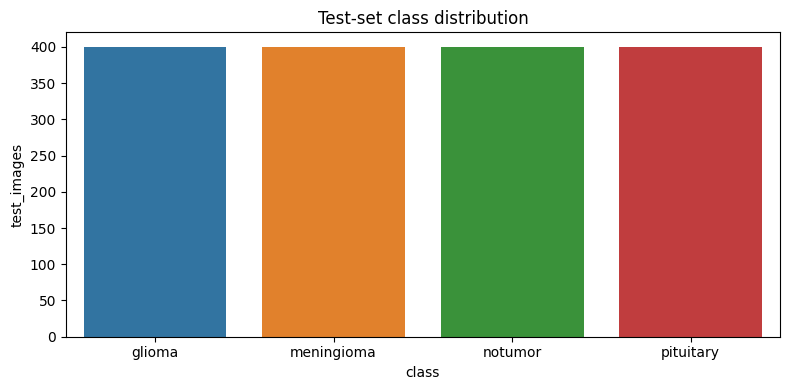

In [22]:
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}
def require_class_folders(folder, label):
    if not folder.is_dir(): raise FileNotFoundError(f"{label} directory not found: {folder}; update paths in Configuration.")
    missing = [c for c in CLASS_NAMES if not (folder / c).is_dir()]
    if missing: raise FileNotFoundError(f"{label} is missing class folder(s) {missing}: {folder}")
def discover_images(folder):
    rows, bad = [], []
    for i, cls in enumerate(CLASS_NAMES):
        for path in sorted((folder / cls).rglob("*"), key=lambda p: str(p).lower()):
            if not path.is_file() or path.suffix.lower() not in VALID_EXTENSIONS: continue
            try:
                with Image.open(path) as im: im.verify()
                with Image.open(path) as im: w, h, mode, channels = im.width, im.height, im.mode, len(im.getbands())
                rows.append({"image_path":str(path), "true_label":i, "true_class":cls,
                             "width":w, "height":h, "image_mode":mode, "channels":channels})
            except (OSError, ValueError) as exc: bad.append({"image_path":str(path), "error":str(exc)})
    return pd.DataFrame(rows), pd.DataFrame(bad)
require_class_folders(TRAIN_DIR, "Training"); require_class_folders(TEST_DIR, "Test")
train_manifest, train_corrupt = discover_images(TRAIN_DIR)
test_manifest, corrupt_manifest = discover_images(TEST_DIR)
if test_manifest.empty: raise ValueError(f"No readable test images found in {TEST_DIR}")
train_counts=train_manifest.groupby("true_class").size().reindex(CLASS_NAMES,fill_value=0)
test_counts=test_manifest.groupby("true_class").size().reindex(CLASS_NAMES,fill_value=0)
audit=pd.DataFrame({"class":CLASS_NAMES,"train_images":train_counts.to_numpy(),"test_images":test_counts.to_numpy()})
audit["total_images"]=audit.train_images+audit.test_images
audit["test_percentage"]=100*audit.test_images/audit.test_images.sum()
print("Classes:", NUM_CLASSES, "| total train:", len(train_manifest), "| total test:", len(test_manifest))
display(audit)
display(test_manifest.groupby(["width", "height", "channels", "image_mode"]).size().rename("count").reset_index().head(20))
print("Unreadable train/test:", len(train_corrupt), len(corrupt_manifest))
if len(corrupt_manifest): display(corrupt_manifest.head(20))
fig, ax = plt.subplots(figsize=(8,4)); sns.barplot(data=audit, x="class", y="test_images", hue="class", legend=False, ax=ax)
ax.set_title("Test-set class distribution"); plt.tight_layout()
fig.savefig(OUTPUT_DIRS["figures"] / "test_class_distribution.png", dpi=150); plt.show()

## 7. Dataset Visualization

Display representative test images from every class. No medical appearance is inferred from visualization.

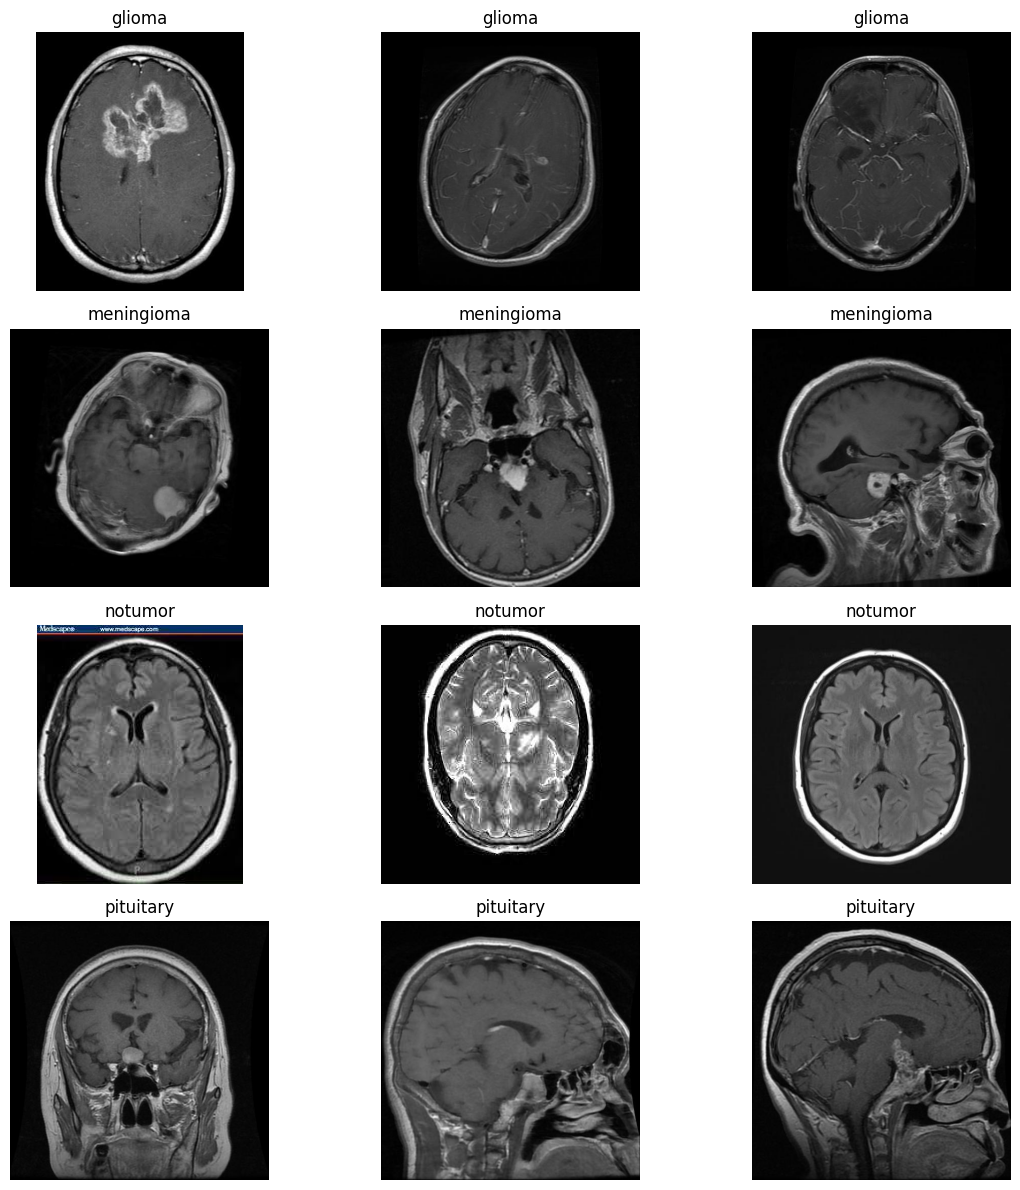

In [23]:
fig, axes = plt.subplots(NUM_CLASSES, 3, figsize=(12,12))
for row, cls in enumerate(CLASS_NAMES):
    sample = test_manifest[test_manifest.true_class == cls].head(3)
    for col in range(3):
        axes[row,col].axis("off")
        if col < len(sample):
            with Image.open(sample.iloc[col].image_path) as im: axes[row,col].imshow(im.convert("RGB"))
            axes[row,col].set_title(cls)
plt.tight_layout(); plt.show()

## 8. Data Preprocessing

Both networks receive the same resized 224 × 224 RGB samples in the same fixed order. Model preprocessing is selected per saved checkpoint: `raw_0_255`, `resnet50`, or `vgg16`. The application preprocessors are architecture-specific. Current checkpoints were inspected and evaluated with raw 0–255 float32 tensors; no explicit preprocessing layer was found. The test data is never augmented.

In [24]:
def load_rgb_batch(manifest):
    images = []
    for path in manifest.image_path:
        with Image.open(path) as im:
            im = im.convert("RGB").resize((IMG_SIZE[1], IMG_SIZE[0]), Image.Resampling.BILINEAR)
            images.append(np.asarray(im, dtype=np.float32))
    return np.stack(images), manifest.true_label.to_numpy(dtype=np.int64)
def preprocess_for_model(images, model_name):
    mode = INPUT_PREPROCESSING[model_name]
    if mode == "raw_0_255": return images.astype(np.float32, copy=False)
    if mode == "resnet50": return tf.keras.applications.resnet50.preprocess_input(images.astype(np.float32))
    if mode == "vgg16": return tf.keras.applications.vgg16.preprocess_input(images.astype(np.float32))
    raise ValueError(f"Unsupported preprocessing mode for {model_name}: {mode}")
X_test_rgb, y_test = load_rgb_batch(test_manifest)
X_resnet = preprocess_for_model(X_test_rgb, "resnet50")
X_vgg = preprocess_for_model(X_test_rgb, "vgg16")
print("Test tensor:", X_test_rgb.shape, X_resnet.dtype, X_vgg.dtype)

Test tensor: (1600, 224, 224, 3) float32 float32


## 9. Load Existing ResNet50 Model

In [25]:
def load_trained_model(model_path):
    if not Path(model_path).is_file(): raise FileNotFoundError(f"Trained model not found: {model_path}")
    return tf.keras.models.load_model(model_path, compile=False)
resnet_model = load_trained_model(RESNET_MODEL_PATH)
print("ResNet50 summary:"); resnet_model.summary()
print("Input/output:", resnet_model.input_shape, resnet_model.output_shape)
print("Parameters total/trainable/non-trainable:", resnet_model.count_params(),
      sum(int(np.prod(v.shape)) for v in resnet_model.trainable_variables),
      sum(int(np.prod(v.shape)) for v in resnet_model.non_trainable_variables))

ResNet50 summary:


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,121,476 (92.02 MB)

 Trainable params: 14,958,340 (57.06 MB)

 Non-trainable params: 9,163,136 (34.95 MB)

Input/output: (None, 224, 224, 3) (None, 4)
Parameters total/trainable/non-trainable: 24121476 14958340 9163144


## 10. Load Existing VGG16 Model

In [26]:
vgg_model = load_trained_model(VGG16_MODEL_PATH)
print("VGG16 summary:"); vgg_model.summary()
print("Input/output:", vgg_model.input_shape, vgg_model.output_shape)
print("Parameters total/trainable/non-trainable:", vgg_model.count_params(),
      sum(int(np.prod(v.shape)) for v in vgg_model.trainable_variables),
      sum(int(np.prod(v.shape)) for v in vgg_model.non_trainable_variables))

VGG16 summary:


Model: "functional_18"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_15 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_7      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,849,092 (56.64 MB)

 Trainable params: 14,848,068 (56.64 MB)

 Non-trainable params: 1,024 (4.00 KB)

Input/output: (None, 224, 224, 3) (None, 4)
Parameters total/trainable/non-trainable: 14849092 14848068 1032


## 11. Verify Model Compatibility

Both models must accept 224 × 224 × 3 images and emit four outputs. Outputs already summing to one are treated as probabilities; otherwise stable softmax normalization is applied. Invalid outputs raise errors.

In [27]:
def get_probabilities(model, x, batch_size=BATCH_SIZE):
    outputs = np.asarray(model.predict(x, batch_size=batch_size, verbose=0), dtype=np.float64)
    if outputs.ndim != 2 or outputs.shape[1] != NUM_CLASSES: raise ValueError(f"Expected (N,{NUM_CLASSES}) output, got {outputs.shape}")
    if not np.isfinite(outputs).all(): raise ValueError("Model produced non-finite outputs")
    if np.all(outputs >= 0) and np.all(outputs <= 1) and np.allclose(outputs.sum(1), 1, atol=1e-3): return outputs
    z = outputs - outputs.max(axis=1, keepdims=True); e = np.exp(z); return e / e.sum(axis=1, keepdims=True)
for name, model in [("ResNet50",resnet_model),("VGG16",vgg_model)]:
    if tuple(model.input_shape[1:]) != IMG_SIZE + (3,): raise ValueError(f"{name} input incompatible: {model.input_shape}")
    if model.output_shape[-1] != NUM_CLASSES: raise ValueError(f"{name} output incompatible: {model.output_shape}")
    print(name, "compatibility passed")

ResNet50 compatibility passed
VGG16 compatibility passed


## 12. Baseline Evaluation

Metrics and confusion matrices use identical samples. ROC-AUC is macro one-vs-rest; unavailable values remain null.

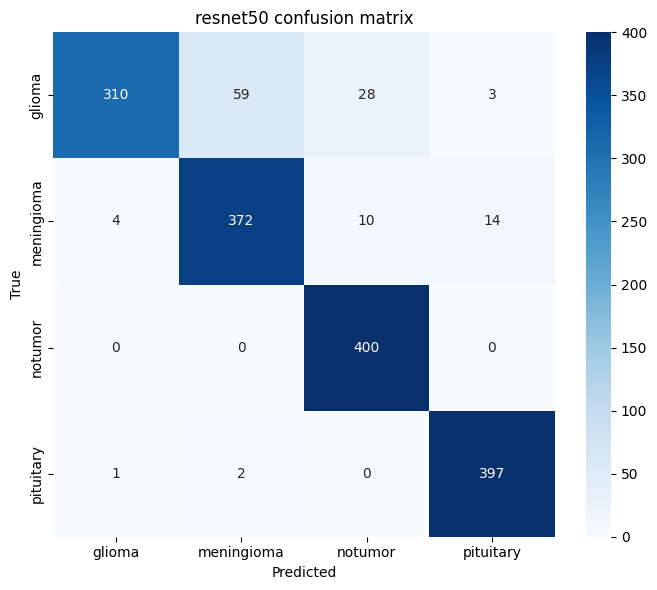

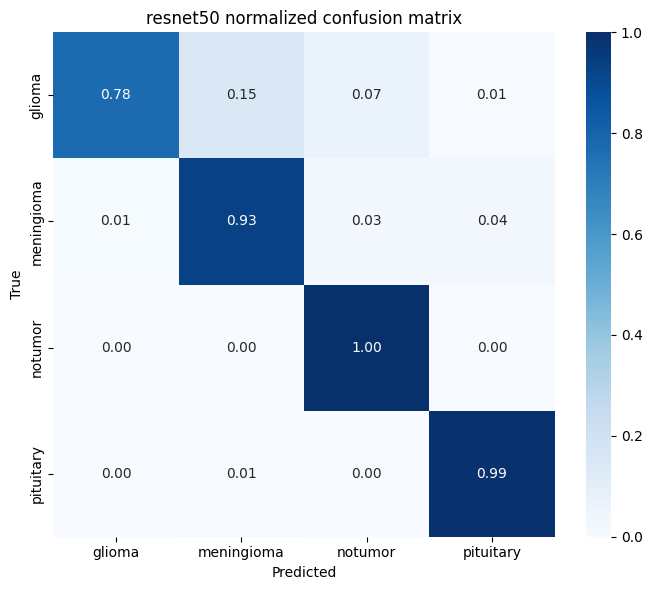

resnet50 {'accuracy': 0.924375, 'macro_precision': 0.928857148293653, 'macro_recall': 0.9243750000000001, 'macro_f1': 0.9225935108538746, 'weighted_f1': 0.9225935108538746, 'roc_auc_ovr_macro': 0.9833203125000001, 'ece': 0.04459670960903169, 'brier_score': 0.1285930429492352, 'mean_normalized_entropy': 0.0742085278296765, 'normalized_confusion_matrix': [[0.775, 0.1475, 0.07, 0.0075], [0.01, 0.93, 0.025, 0.035], [0.0, 0.0, 1.0, 0.0], [0.0025, 0.005, 0.0, 0.9925]]}


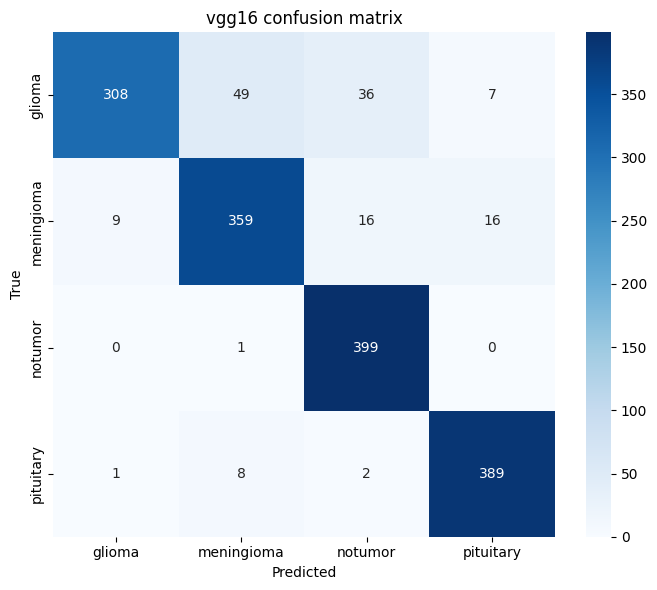

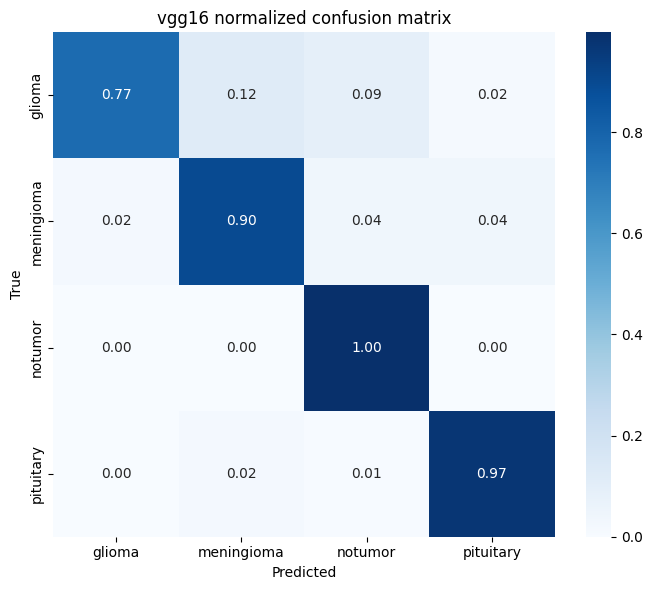

vgg16 {'accuracy': 0.909375, 'macro_precision': 0.9136085473427547, 'macro_recall': 0.909375, 'macro_f1': 0.9076033637600922, 'weighted_f1': 0.9076033637600922, 'roc_auc_ovr_macro': 0.9818619791666666, 'ece': 0.026959321741014744, 'brier_score': 0.13440556882910093, 'mean_normalized_entropy': 0.14739165761854792, 'normalized_confusion_matrix': [[0.77, 0.1225, 0.09, 0.0175], [0.0225, 0.8975, 0.04, 0.04], [0.0, 0.0025, 0.9975, 0.0], [0.0025, 0.02, 0.005, 0.9725]]}


In [28]:
def calculate_entropy(probabilities):
    p = np.clip(np.asarray(probabilities, dtype=np.float64), 1e-12, 1)
    return -np.sum(p * np.log(p), axis=1)
def normalized_entropy(probabilities): return calculate_entropy(probabilities) / np.log(NUM_CLASSES)
def calculate_ece(probabilities, labels, n_bins=15):
    conf = probabilities.max(1); correct = probabilities.argmax(1) == labels; edges = np.linspace(0,1,n_bins+1); ece = 0.
    for lo,hi in zip(edges[:-1], edges[1:]):
        mask = (conf > lo) & (conf <= hi if hi < 1 else conf <= hi)
        if mask.any(): ece += mask.mean() * abs(correct[mask].mean() - conf[mask].mean())
    return float(ece)
def calculate_brier_score(probabilities, labels): return float(np.mean(np.sum((probabilities - np.eye(NUM_CLASSES)[labels])**2, axis=1)))
def evaluate_probabilities(probabilities, labels):
    pred = probabilities.argmax(1)
    report = classification_report(labels, pred, labels=np.arange(NUM_CLASSES), target_names=CLASS_NAMES, output_dict=True, zero_division=0)
    try: auc = float(roc_auc_score(np.eye(NUM_CLASSES)[labels], probabilities, average="macro", multi_class="ovr"))
    except ValueError: auc = None
    return {"accuracy":float(accuracy_score(labels,pred)),
        "macro_precision":float(precision_score(labels,pred,average="macro",zero_division=0)),
        "macro_recall":float(recall_score(labels,pred,average="macro",zero_division=0)),
        "macro_f1":float(f1_score(labels,pred,average="macro",zero_division=0)),
        "weighted_f1":float(f1_score(labels,pred,average="weighted",zero_division=0)),
        "roc_auc_ovr_macro":auc,"ece":calculate_ece(probabilities,labels),"brier_score":calculate_brier_score(probabilities,labels),
        "mean_normalized_entropy":float(normalized_entropy(probabilities).mean()),"report":report,
        "confusion_matrix":confusion_matrix(labels,pred,labels=np.arange(NUM_CLASSES)).tolist(),
        "normalized_confusion_matrix":confusion_matrix(labels,pred,labels=np.arange(NUM_CLASSES),normalize="true").tolist(),
        "predictions":pred}
def plot_confusion_matrix(cm, title, path):
    fmt=".2f" if np.issubdtype(np.asarray(cm).dtype,np.floating) else "d"
    fig,ax=plt.subplots(figsize=(7,6)); sns.heatmap(cm,annot=True,fmt=fmt,cmap="Blues",xticklabels=CLASS_NAMES,yticklabels=CLASS_NAMES,ax=ax)
    ax.set(title=title,xlabel="Predicted",ylabel="True"); fig.tight_layout(); fig.savefig(path,dpi=150); plt.show()
p_resnet=get_probabilities(resnet_model,X_resnet); p_vgg=get_probabilities(vgg_model,X_vgg)
resnet_eval=evaluate_probabilities(p_resnet,y_test); vgg_eval=evaluate_probabilities(p_vgg,y_test)
for name,result in [("resnet50",resnet_eval),("vgg16",vgg_eval)]:
    (OUTPUT_DIRS["metrics"] / f"{name}_classification_report.json").write_text(json.dumps(result["report"],indent=2))
    plot_confusion_matrix(result["confusion_matrix"],f"{name} confusion matrix",OUTPUT_DIRS["figures"] / f"{name}_confusion_matrix.png")
    plot_confusion_matrix(result["normalized_confusion_matrix"],f"{name} normalized confusion matrix",OUTPUT_DIRS["figures"] / f"{name}_normalized_confusion_matrix.png")
    print(name,{k:v for k,v in result.items() if k not in {"report","confusion_matrix","predictions"}})

## 13. Probability Extraction

The per-image table stores true labels, probability vectors, predictions, confidence, entropy, correctness, and model agreement.

In [29]:
def make_prediction_table(manifest, labels, pr, pv):
    rp,vp=pr.argmax(1),pv.argmax(1)
    return pd.DataFrame({"image_path":manifest.image_path.to_numpy(),"true_class":[CLASS_NAMES[i] for i in labels],"true_label":labels,
        "resnet_probabilities":[r.tolist() for r in pr],"vgg_probabilities":[r.tolist() for r in pv],
        "resnet_prediction":[CLASS_NAMES[i] for i in rp],"vgg_prediction":[CLASS_NAMES[i] for i in vp],
        "resnet_confidence":pr.max(1),"vgg_confidence":pv.max(1),"resnet_entropy":normalized_entropy(pr),"vgg_entropy":normalized_entropy(pv),
        "resnet_correct":rp==labels,"vgg_correct":vp==labels,"agreement":rp==vp})
predictions_df=make_prediction_table(test_manifest,y_test,p_resnet,p_vgg)
predictions_df.to_csv(OUTPUT_DIRS["predictions"] / "dual_model_predictions.csv",index=False)
display(predictions_df.head())

,image_path,true_class,true_label,resnet_probabilities,vgg_probabilities,resnet_prediction,vgg_prediction,resnet_confidence,vgg_confidence,resnet_entropy,vgg_entropy,resnet_correct,vgg_correct,agreement
0,e:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,glioma,0,"[0.025765329599380493, 0.019825726747512817, 0...","[0.9571914672851562, 0.011694935150444508, 0.0...",notumor,glioma,0.943400,0.957191,0.199531,0.152185,False,True,False
1,e:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,glioma,0,"[0.9999998807907104, 1.0250312953985485e-07, 1...","[0.9995335340499878, 1.5233848898787983e-05, 0...",glioma,glioma,1.000000,0.999534,0.000002,0.002992,True,True,True
2,e:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,glioma,0,"[0.9999996423721313, 1.452129438916927e-08, 4....","[0.9940349459648132, 0.0002887363953050226, 0....",glioma,glioma,1.000000,0.994035,0.000005,0.028355,True,True,True
3,e:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,glioma,0,"[0.7186024188995361, 0.2067427635192871, 0.000...","[0.33576709032058716, 0.5979446768760681, 0.03...",glioma,meningioma,0.718602,0.597945,0.547355,0.648929,True,False,False
4,e:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,glioma,0,"[0.34256109595298767, 0.039696577936410904, 0....","[0.23743705451488495, 0.014542318880558014, 0....",notumor,notumor,0.577821,0.744944,0.678485,0.461709,False,False,True


## 14. Dual-Model Ensemble

Soft-voting weight is selected on validation data only. With no validation split, use prespecified equal weighting (α=0.5); never tune on final test data. An additional adaptive variant weights each model by its own top-class confidence; it is an exploratory test-time rule, not a validation-tuned method. Calibration temperature is also fit only with validation data.

No validation split. Using prespecified alpha=0.5; no test-set tuning performed.


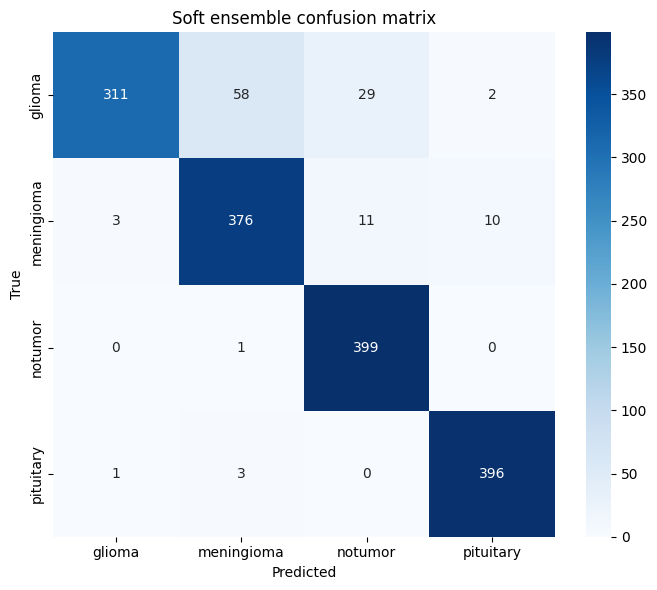

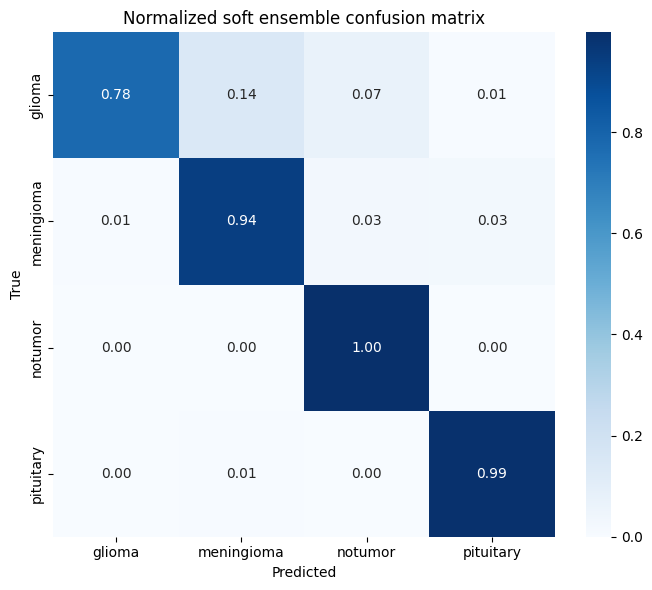

In [30]:
def soft_ensemble(prob_r,prob_v,alpha): return alpha*prob_r+(1-alpha)*prob_v
has_validation=VAL_DIR.is_dir() and all((VAL_DIR/c).is_dir() for c in CLASS_NAMES)
if has_validation:
    val_manifest,val_corrupt=discover_images(VAL_DIR)
    if val_manifest.empty: raise ValueError(f"Validation directory has no readable images: {VAL_DIR}")
    X_val_rgb,y_val=load_rgb_batch(val_manifest)
    p_resnet_val=get_probabilities(resnet_model,preprocess_for_model(X_val_rgb,"resnet50"))
    p_vgg_val=get_probabilities(vgg_model,preprocess_for_model(X_val_rgb,"vgg16"))
    alpha_scores=[(float(a),evaluate_probabilities(soft_ensemble(p_resnet_val,p_vgg_val,float(a)),y_val)["macro_f1"]) for a in np.linspace(0,1,11)]
    best_alpha=max(alpha_scores,key=lambda x:x[1])[0]
else:
    p_resnet_val=p_vgg_val=y_val=None; best_alpha=0.5; alpha_scores=[]
    print("No validation split. Using prespecified alpha=0.5; no test-set tuning performed.")
p_ensemble=soft_ensemble(p_resnet,p_vgg,best_alpha)
ensemble_eval=evaluate_probabilities(p_ensemble,y_test)
adaptive_alpha=p_resnet.max(1)/(p_resnet.max(1)+p_vgg.max(1)+1e-12)
p_adaptive=adaptive_alpha[:,None]*p_resnet+(1-adaptive_alpha[:,None])*p_vgg
adaptive_eval=evaluate_probabilities(p_adaptive,y_test)
predictions_df["adaptive_prediction"]=[CLASS_NAMES[i] for i in p_adaptive.argmax(1)]
predictions_df["adaptive_confidence"]=p_adaptive.max(1)
predictions_df["adaptive_entropy"]=normalized_entropy(p_adaptive)
plot_confusion_matrix(ensemble_eval["confusion_matrix"],"Soft ensemble confusion matrix",OUTPUT_DIRS["figures"] / "ensemble_confusion_matrix.png")
plot_confusion_matrix(ensemble_eval["normalized_confusion_matrix"],"Normalized soft ensemble confusion matrix",OUTPUT_DIRS["figures"] / "ensemble_normalized_confusion_matrix.png")
if alpha_scores: display(pd.DataFrame(alpha_scores,columns=["alpha_resnet","validation_macro_f1"]))

## 15. Model Agreement and Disagreement Analysis

Group counts and correctness are computed from paired predictions. Descriptive patterns on this dataset do not establish generalization.

In [31]:
r_pred,v_pred=p_resnet.argmax(1),p_vgg.argmax(1); r_ok,v_ok=r_pred==y_test,v_pred==y_test; agreement=r_pred==v_pred
case_masks={"Both correct":r_ok&v_ok,"Both wrong":~r_ok&~v_ok,"ResNet correct / VGG wrong":r_ok&~v_ok,
 "ResNet wrong / VGG correct":~r_ok&v_ok,"Agree on incorrect prediction":agreement&~r_ok,"Disagree":~agreement}
rows=[]
for name,mask in case_masks.items():
    n=int(mask.sum()); rows.append({"case_type":name,"count":n,"percentage":100*n/len(y_test),
        "accuracy_within_case":float((r_ok[mask]&v_ok[mask]).mean()) if n else np.nan})
agreement_table=pd.DataFrame(rows); agreement_rate=float(agreement.mean()); disagreement_rate=1-agreement_rate
display(agreement_table); print("Agreement/disagreement:",agreement_rate,disagreement_rate)
ensemble_correct=p_ensemble.argmax(1)==y_test
print("Ensemble error rate on agreeing/disagreeing cases:",
      float((~ensemble_correct[agreement]).mean()) if agreement.any() else np.nan,
      float((~ensemble_correct[~agreement]).mean()) if (~agreement).any() else np.nan)


,case_type,count,percentage,accuracy_within_case
0,Both correct,1428,89.2500,1.0
1,Both wrong,94,5.8750,0.0
2,ResNet correct / VGG wrong,51,3.1875,0.0
3,ResNet wrong / VGG correct,27,1.6875,0.0
4,Agree on incorrect prediction,72,4.5000,0.0
5,Disagree,100,6.2500,0.0


Agreement/disagreement: 0.9375 0.0625
Ensemble error rate on agreeing/disagreeing cases: 0.048 0.46


## 16. Uncertainty Estimation

Normalized entropy H(p)/log(K) ranges from zero to one. Descriptive bins ≤0.33 low, ≤0.66 medium, >0.66 high are not medically validated thresholds.

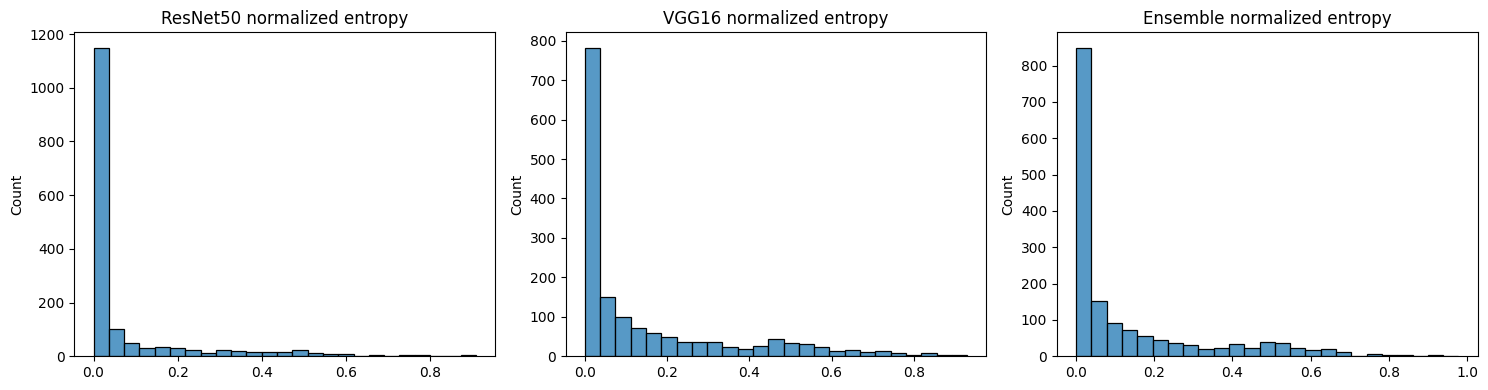

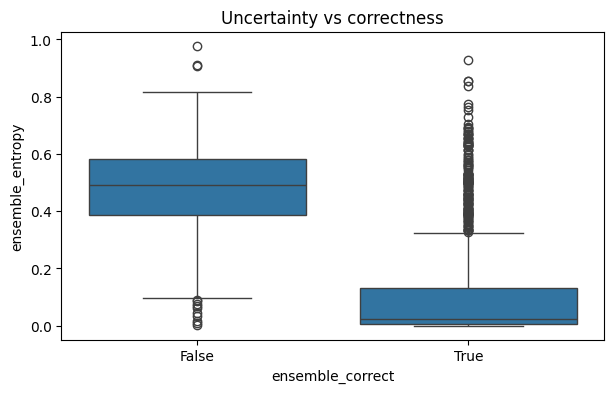

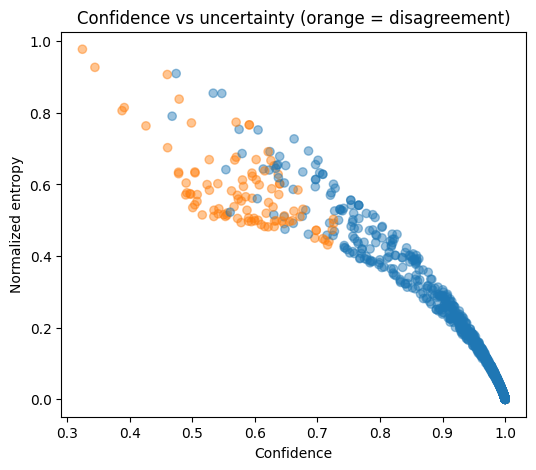

Mean entropy correct/incorrect: {False: 0.461136864092015, True: 0.10578319395437362}


In [32]:
h_r,h_v,h_e=normalized_entropy(p_resnet),normalized_entropy(p_vgg),normalized_entropy(p_ensemble)
predictions_df["ensemble_prediction"]=[CLASS_NAMES[i] for i in p_ensemble.argmax(1)]
predictions_df["ensemble_confidence"]=p_ensemble.max(1); predictions_df["ensemble_entropy"]=h_e
predictions_df["uncertainty_level"]=pd.cut(h_e,[-1e-9,.33,.66,1.000001],labels=["Low","Medium","High"])
predictions_df["ensemble_correct"]=p_ensemble.argmax(1)==y_test
fig,axes=plt.subplots(1,3,figsize=(15,4))
for vals,name,ax in zip([h_r,h_v,h_e],["ResNet50","VGG16","Ensemble"],axes): sns.histplot(vals,bins=25,ax=ax); ax.set_title(name+" normalized entropy")
plt.tight_layout(); plt.show()
fig,ax=plt.subplots(figsize=(7,4)); sns.boxplot(data=predictions_df,x="ensemble_correct",y="ensemble_entropy",ax=ax); ax.set_title("Uncertainty vs correctness"); plt.show()
fig,ax=plt.subplots(figsize=(6,5)); ax.scatter(predictions_df.ensemble_confidence,predictions_df.ensemble_entropy,c=np.where(agreement,"tab:blue","tab:orange"),alpha=.45)
ax.set(xlabel="Confidence",ylabel="Normalized entropy",title="Confidence vs uncertainty (orange = disagreement)"); plt.show()
print("Mean entropy correct/incorrect:",predictions_df.groupby("ensemble_correct").ensemble_entropy.mean().to_dict())

## 17. Confidence Analysis

Compare confidence by correctness and agreement, and inspect empirical accuracy across confidence bins. Confidence is not automatically a calibrated correctness probability.

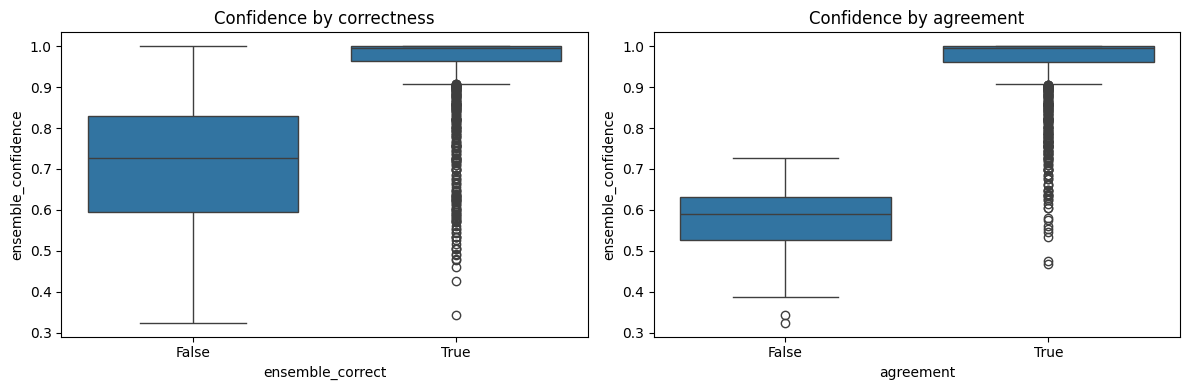

,count,mean
ensemble_confidence,,
"(-0.001, 0.1]",0,NaN
"(0.1, 0.2]",0,NaN
"(0.2, 0.3]",0,NaN
"(0.3, 0.4]",4,0.250000
"(0.4, 0.5]",14,0.428571
"(0.5, 0.6]",49,0.591837
"(0.6, 0.7]",61,0.606557
"(0.7, 0.8]",75,0.640000
"(0.8, 0.9]",96,0.833333


In [33]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
sns.boxplot(data=predictions_df,x="ensemble_correct",y="ensemble_confidence",ax=axes[0]); axes[0].set_title("Confidence by correctness")
sns.boxplot(data=predictions_df,x="agreement",y="ensemble_confidence",ax=axes[1]); axes[1].set_title("Confidence by agreement")
plt.tight_layout(); plt.show()
bins=pd.cut(predictions_df.ensemble_confidence,np.linspace(0,1,11),include_lowest=True)
display(predictions_df.groupby(bins,observed=False).ensemble_correct.agg(["count","mean"]))

## 18. Probability Calibration and Reliability Analysis

Reliability diagrams compare average confidence to empirical accuracy. ECE and multiclass Brier score are descriptive. A scalar temperature is selected on validation negative log-likelihood only, if validation exists; otherwise calibration fitting is skipped.

No validation data: no calibration fitting; test set is not used to fit parameters.


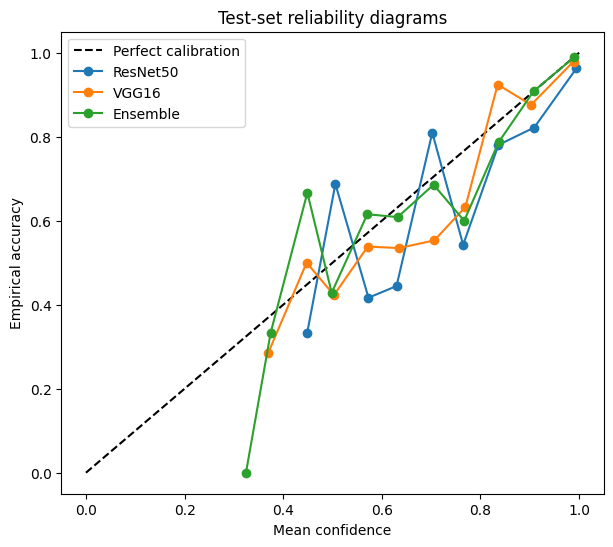

,model,ECE,Brier,validation_temperature
0,ResNet50,0.044597,0.128593,None
1,VGG16,0.026959,0.134406,None
2,Ensemble,0.011900,0.116040,None


Calibrated test results skipped: no validation data to fit temperature scaling.


In [34]:
def reliability_data(probabilities,labels,bins=15):
    conf=probabilities.max(1); correct=probabilities.argmax(1)==labels; edges=np.linspace(0,1,bins+1); rows=[]
    for lo,hi in zip(edges[:-1],edges[1:]):
        m=(conf>lo)&(conf<=hi if hi<1 else conf<=hi)
        if m.any(): rows.append({"confidence":conf[m].mean(),"accuracy":correct[m].mean(),"count":int(m.sum())})
    return pd.DataFrame(rows)
def temperature_scale(probabilities,t):
    z=np.log(np.clip(probabilities,1e-12,1))/t; z-=z.max(1,keepdims=True); e=np.exp(z); return e/e.sum(1,keepdims=True)
def nll(probabilities,labels): return float(-np.log(np.clip(probabilities[np.arange(len(labels)),labels],1e-12,1)).mean())
probability_sets={"ResNet50":p_resnet,"VGG16":p_vgg,"Ensemble":p_ensemble}
if has_validation:
    val_sets={"ResNet50":p_resnet_val,"VGG16":p_vgg_val,"Ensemble":soft_ensemble(p_resnet_val,p_vgg_val,best_alpha)}
    temperatures={name:float(min(np.linspace(.5,3,51),key=lambda t:nll(temperature_scale(p,t),y_val))) for name,p in val_sets.items()}
else:
    temperatures={}; print("No validation data: no calibration fitting; test set is not used to fit parameters.")
fig,ax=plt.subplots(figsize=(7,6)); ax.plot([0,1],[0,1],"k--",label="Perfect calibration")
calibration_rows=[]
for name,probs in probability_sets.items():
    rd=reliability_data(probs,y_test); ax.plot(rd.confidence,rd.accuracy,marker="o",label=name)
    calibration_rows.append({"model":name,"ECE":calculate_ece(probs,y_test),"Brier":calculate_brier_score(probs,y_test),"validation_temperature":temperatures.get(name)})
ax.set(xlabel="Mean confidence",ylabel="Empirical accuracy",title="Test-set reliability diagrams"); ax.legend(); plt.show()
calibration_table=pd.DataFrame(calibration_rows); display(calibration_table)
calibration_table.to_csv(OUTPUT_DIRS["metrics"] / "calibration_results.csv",index=False)
if has_validation:
    calibrated_probability_sets={name:temperature_scale(probs,temperatures[name]) for name,probs in probability_sets.items()}
    calibrated_metrics=pd.DataFrame([{"model":name,"temperature_fit_on":"validation",
        "test_accuracy":evaluate_probabilities(probs,y_test)["accuracy"],"test_ECE":calculate_ece(probs,y_test),
        "test_Brier":calculate_brier_score(probs,y_test)} for name,probs in calibrated_probability_sets.items()])
    display(calibrated_metrics)
    calibrated_metrics.to_csv(OUTPUT_DIRS["metrics"] / "calibrated_test_results.csv",index=False)
else:
    calibrated_probability_sets={}
    print("Calibrated test results skipped: no validation data to fit temperature scaling.")

## 19. Grad-CAM Explainability

Grad-CAM uses gradients of a class score with respect to the last convolution in each nested backbone. Examples are selected from both-correct agreement, disagreement, agreed error, high uncertainty, and high-confidence error when available. Heatmaps show activation sensitivity, not medically correct tumor localization.

In [35]:
def find_backbone_and_conv(model,preferred_name):
    candidates=[layer for layer in model.layers if isinstance(layer,tf.keras.Model)]
    backbone=next((x for x in candidates if preferred_name in x.name.lower()),candidates[0] if candidates else None)
    if backbone is None: raise ValueError(f"No nested feature extractor found in {model.name}; Grad-CAM unsupported")
    conv=[x for x in backbone.layers if isinstance(x,tf.keras.layers.Conv2D)]
    if not conv: raise ValueError(f"No Conv2D layer found inside {backbone.name}")
    return backbone,conv[-1]
def generate_gradcam(model,image_rgb,model_name,class_index=None):
    backbone,conv=find_backbone_and_conv(model,model_name)
    grad_model=tf.keras.Model(backbone.input,[conv.output,backbone.output]); outer=model.layers.index(backbone)
    with tf.GradientTape() as tape:
        x=tf.convert_to_tensor(preprocess_for_model(image_rgb[None,...],model_name))
        for layer in model.layers[1:outer]: x=layer(x,training=False)
        activations,x=grad_model(x,training=False)
        for layer in model.layers[outer+1:]: x=layer(x,training=False)
        target=int(tf.argmax(x[0])) if class_index is None else int(class_index)
        score=x[:,target]
    grads=tape.gradient(score,activations)
    if grads is None: raise RuntimeError(f"Grad-CAM gradients unavailable for {model_name}")
    weights=tf.reduce_mean(grads,axis=(1,2),keepdims=True); cam=tf.maximum(tf.reduce_sum(weights*activations,axis=-1)[0],0)
    maximum=tf.reduce_max(cam); return (cam/maximum).numpy() if float(maximum)>0 else cam.numpy()
def overlay_heatmap(image,cam,alpha=.4):
    resized=Image.fromarray(np.uint8(np.clip(cam,0,1)*255)).resize((image.shape[1],image.shape[0]))
    colors=plt.get_cmap("jet")(np.asarray(resized)/255.)[...,:3]
    return np.clip((1-alpha)*image/255.+alpha*colors,0,1)


## 20. Quantitative Explanation Comparison

No segmentation masks are available, so localization IoU/coverage is not calculated. Heatmap correlation and cosine similarity are explanation-consistency measures only.

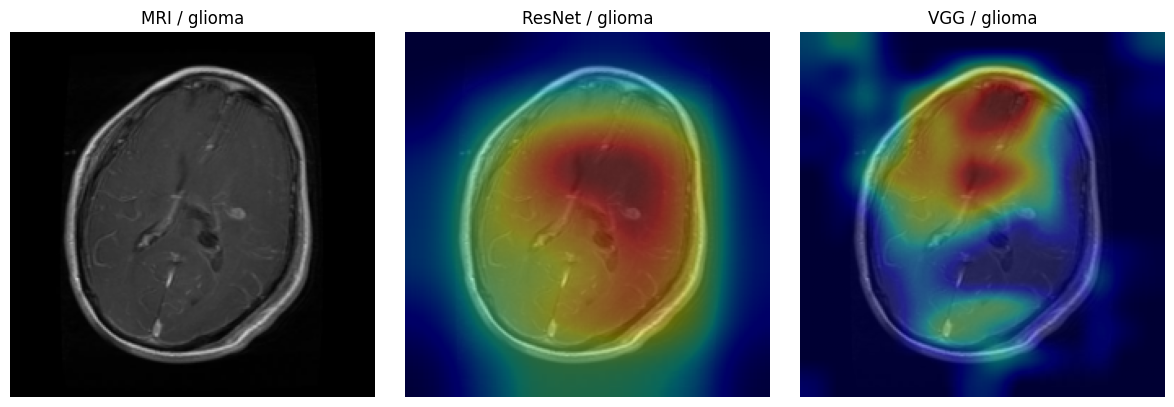

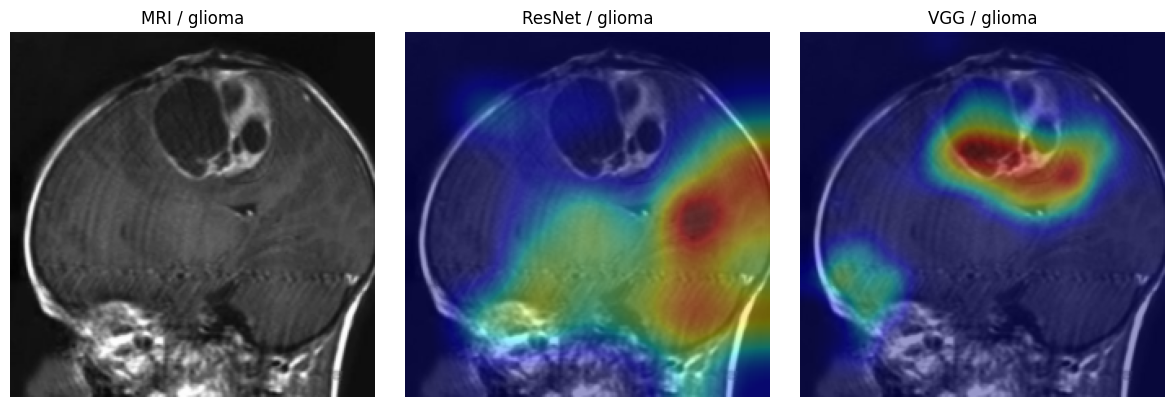

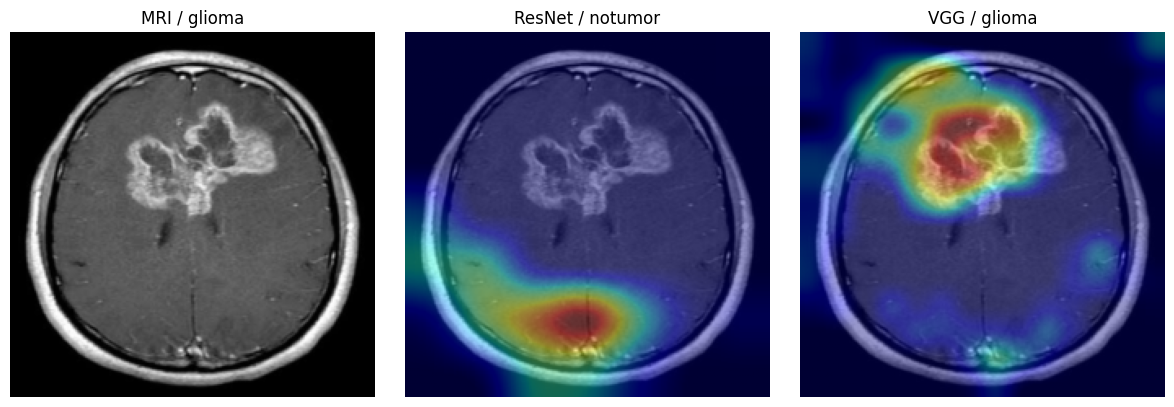

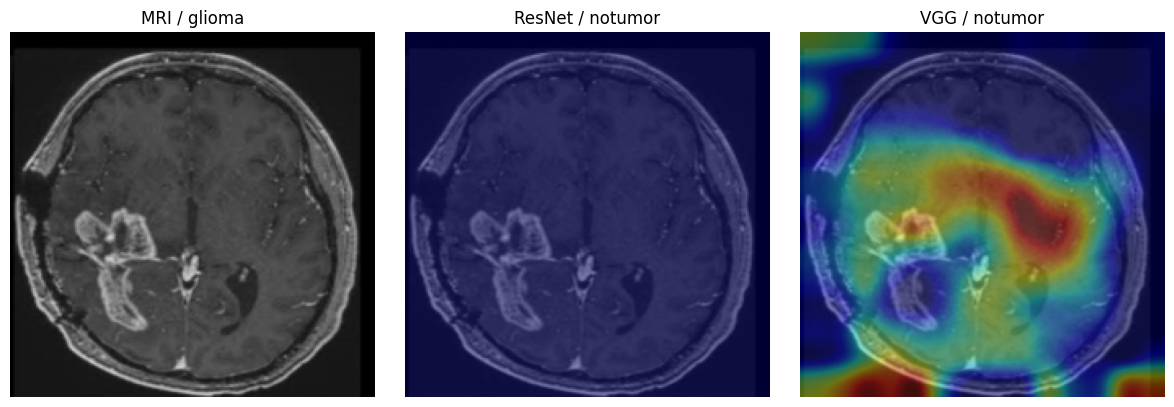

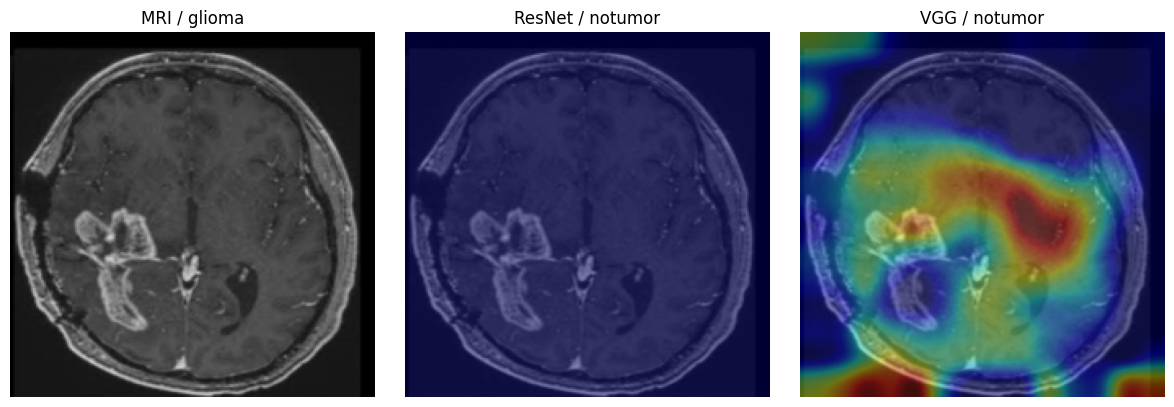

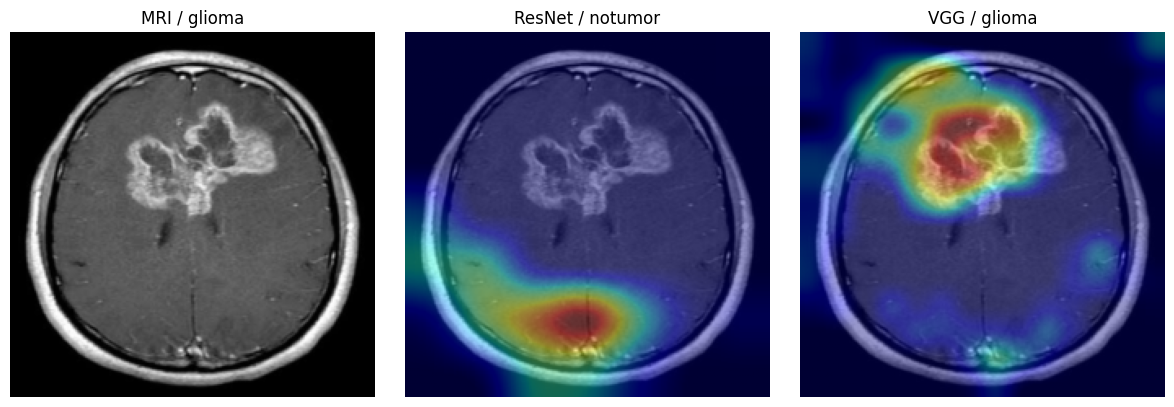

,sample_type,index,heatmap_correlation,cosine_similarity
0,both_correct_agree,1,0.504373,0.754887
1,both_correct_confidence_gap,5,-0.113533,0.248076
2,disagreement,0,-0.160712,0.161922
3,agree_wrong,4,NaN,NaN
4,both_models_wrong,4,NaN,NaN
5,high_uncertainty,0,-0.160712,0.161922


In [36]:
def calculate_explanation_similarity(map_a,map_b,target_size=IMG_SIZE):
    map_a,map_b=np.asarray(map_a,dtype=np.float32),np.asarray(map_b,dtype=np.float32)
    if map_a.ndim!=2 or map_b.ndim!=2:
        raise ValueError(f"Expected 2D Grad-CAM maps; got {map_a.shape} and {map_b.shape}")
    if 0 in map_a.shape or 0 in map_b.shape:
        raise ValueError(f"Grad-CAM maps must be non-empty; got {map_a.shape} and {map_b.shape}")
    # Backbones may produce different map grids (for example 7x7 vs 14x14).
    # Resize both maps to the MRI resolution before paired spatial comparison.
    a=tf.image.resize(map_a[...,None],target_size,method="bilinear").numpy().squeeze()
    b=tf.image.resize(map_b[...,None],target_size,method="bilinear").numpy().squeeze()
    a,b=a.ravel(),b.ravel()
    corr=float(np.corrcoef(a,b)[0,1]) if np.std(a)>0 and np.std(b)>0 else np.nan
    denom=np.linalg.norm(a)*np.linalg.norm(b); cosine=float(np.dot(a,b)/denom) if denom else np.nan
    return {"heatmap_correlation":corr,"cosine_similarity":cosine}
confidence_gap=np.abs(p_resnet.max(1)-p_vgg.max(1))
cam_groups=[agreement&r_ok&v_ok,(r_ok&v_ok)&(confidence_gap>=np.quantile(confidence_gap,.9)),
            ~agreement,agreement&~r_ok,~r_ok&~v_ok,h_e>=np.quantile(h_e,.9),
            (p_ensemble.max(1)>=np.quantile(p_ensemble.max(1),.95))&~(p_ensemble.argmax(1)==y_test)]
cam_names=["both_correct_agree","both_correct_confidence_gap","disagreement","agree_wrong",
           "both_models_wrong","high_uncertainty","high_confidence_wrong"]
cam_samples=[]
for name,mask in zip(cam_names,cam_groups):
    found=np.flatnonzero(mask)
    if len(found): cam_samples.append((name,int(found[0])))
explanation_rows=[]
for name,idx in cam_samples[:CAM_SAMPLE_LIMIT]:
    cr=generate_gradcam(resnet_model,X_test_rgb[idx],"resnet50",int(r_pred[idx]))
    cv=generate_gradcam(vgg_model,X_test_rgb[idx],"vgg16",int(v_pred[idx]))
    explanation_rows.append({"sample_type":name,"index":idx,**calculate_explanation_similarity(cr,cv)})
    fig,axes=plt.subplots(1,3,figsize=(12,4)); axes[0].imshow(X_test_rgb[idx].astype(np.uint8)); axes[0].set_title("MRI / "+CLASS_NAMES[y_test[idx]])
    axes[1].imshow(overlay_heatmap(X_test_rgb[idx],cr)); axes[1].set_title("ResNet / "+CLASS_NAMES[r_pred[idx]])
    axes[2].imshow(overlay_heatmap(X_test_rgb[idx],cv)); axes[2].set_title("VGG / "+CLASS_NAMES[v_pred[idx]])
    for ax in axes: ax.axis("off")
    fig.tight_layout(); fig.savefig(OUTPUT_DIRS["explanations"] / f"gradcam_{name}_{idx}.png",dpi=140); plt.show()
explanation_similarity_df=pd.DataFrame(explanation_rows); display(explanation_similarity_df)
explanation_similarity_df.to_csv(OUTPUT_DIRS["explanations"] / "explanation_similarity.csv",index=False)

## 21. Image Robustness Testing

Controlled degradations are applied to in-memory copies only; source images are never overwritten. A fixed stratified subset bounds runtime. Stress transformations are not claims about realistic scanner acquisition.

,perturbation,model,accuracy,macro_f1,mean_confidence,mean_entropy,prediction_change_rate,relative_accuracy_degradation
0,Original,ResNet50,0.910156,0.907699,0.959013,0.081659,0.000000,0.000000
1,Original,VGG16,0.886719,0.883966,0.921576,0.154155,0.000000,0.000000
2,Original,Ensemble,0.902344,0.899496,0.930324,0.139216,0.000000,0.000000
3,Gaussian noise,ResNet50,0.421875,0.361305,0.888496,0.198722,0.546875,0.488281
4,Gaussian noise,VGG16,0.480469,0.383334,0.829758,0.291935,0.453125,0.406250
5,Gaussian noise,Ensemble,0.417969,0.384785,0.749083,0.381339,0.546875,0.484375
6,Gaussian blur,ResNet50,0.714844,0.699371,0.920215,0.144594,0.234375,0.195312
7,Gaussian blur,VGG16,0.609375,0.530596,0.824080,0.323077,0.343750,0.277344
8,Gaussian blur,Ensemble,0.687500,0.654830,0.837257,0.296987,0.265625,0.214844
9,Brightness,ResNet50,0.902344,0.900143,0.951277,0.104118,0.027344,0.007812


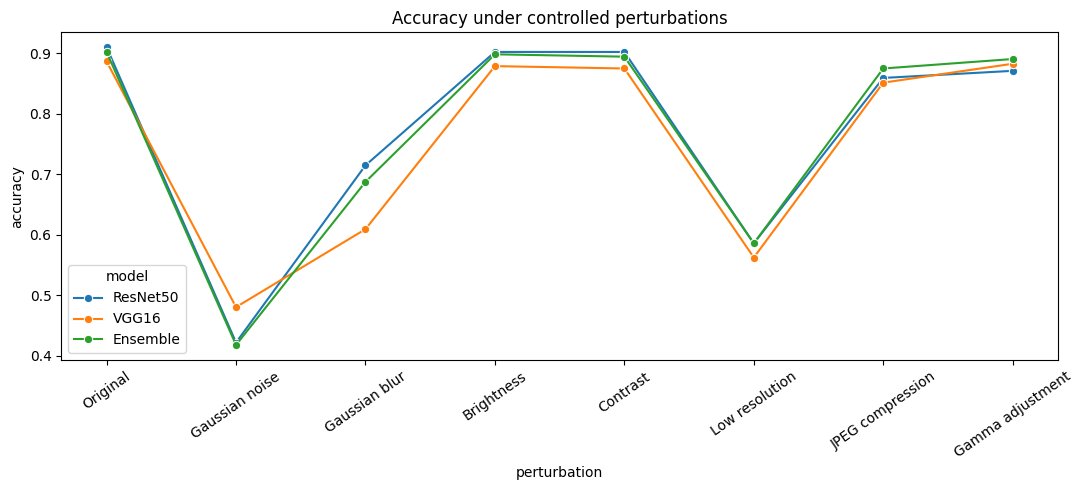

In [37]:
def stratified_indices(labels,limit,seed=SEED):
    if len(labels)<=limit: return np.arange(len(labels))
    selected,_=train_test_split(np.arange(len(labels)),train_size=limit,stratify=labels,random_state=seed)
    return np.sort(selected)
def apply_perturbation(image,kind,seed=SEED):
    rng=np.random.default_rng(seed); image=np.clip(image,0,255).astype(np.uint8); pil=Image.fromarray(image,mode="RGB")
    if kind=="Gaussian noise": return np.clip(image.astype(float)+rng.normal(0,18,image.shape),0,255).astype(np.float32)
    if kind=="Gaussian blur": return np.asarray(pil.filter(ImageFilter.GaussianBlur(radius=1.5)),dtype=np.float32)
    if kind=="Brightness": return np.asarray(ImageEnhance.Brightness(pil).enhance(.75),dtype=np.float32)
    if kind=="Contrast": return np.asarray(ImageEnhance.Contrast(pil).enhance(.65),dtype=np.float32)
    if kind=="Low resolution": return np.asarray(pil.resize((56,56)).resize((IMG_SIZE[1],IMG_SIZE[0])),dtype=np.float32)
    if kind=="JPEG compression":
        buffer=io.BytesIO(); pil.save(buffer,format="JPEG",quality=25); buffer.seek(0)
        with Image.open(buffer) as result: return np.asarray(result.convert("RGB"),dtype=np.float32)
    if kind=="Gamma adjustment": return (255*np.power(image.astype(np.float32)/255,1.4)).astype(np.float32)
    raise ValueError(f"Unknown perturbation: {kind}")
robust_idx=stratified_indices(y_test,ROBUSTNESS_SAMPLE_LIMIT); robust_y=y_test[robust_idx]; clean=X_test_rgb[robust_idx]
perturbations=["Gaussian noise","Gaussian blur","Brightness","Contrast","Low resolution","JPEG compression","Gamma adjustment"]
clean_r=get_probabilities(resnet_model,preprocess_for_model(clean,"resnet50")); clean_v=get_probabilities(vgg_model,preprocess_for_model(clean,"vgg16"))
robust_rows=[]
def record_robustness(label,pr,pv,truth,baseline_r=None,baseline_v=None):
    pe=soft_ensemble(pr,pv,best_alpha)
    for name,p in [("ResNet50",pr),("VGG16",pv),("Ensemble",pe)]:
        ev=evaluate_probabilities(p,truth); base={"ResNet50":baseline_r,"VGG16":baseline_v,"Ensemble":soft_ensemble(baseline_r,baseline_v,best_alpha)}[name] if baseline_r is not None else p
        robust_rows.append({"perturbation":label,"model":name,"accuracy":ev["accuracy"],"macro_f1":ev["macro_f1"],
            "mean_confidence":float(p.max(1).mean()),"mean_entropy":float(normalized_entropy(p).mean()),
            "prediction_change_rate":float(np.mean(p.argmax(1)!=base.argmax(1))) if baseline_r is not None else 0.})
record_robustness("Original",clean_r,clean_v,robust_y)
for kind in perturbations:
    changed=np.stack([apply_perturbation(im,kind,SEED+int(i)) for i,im in zip(robust_idx,clean)])
    pr=get_probabilities(resnet_model,preprocess_for_model(changed,"resnet50")); pv=get_probabilities(vgg_model,preprocess_for_model(changed,"vgg16"))
    record_robustness(kind,pr,pv,robust_y,clean_r,clean_v)
robustness_df=pd.DataFrame(robust_rows)
base=robustness_df[robustness_df.perturbation=="Original"].set_index("model").accuracy
robustness_df["relative_accuracy_degradation"]=robustness_df.apply(lambda row:base[row.model]-row.accuracy,axis=1)
display(robustness_df); robustness_df.to_csv(OUTPUT_DIRS["robustness"] / "robustness_results.csv",index=False)
fig,ax=plt.subplots(figsize=(11,5)); sns.lineplot(data=robustness_df,x="perturbation",y="accuracy",hue="model",marker="o",ax=ax)
ax.tick_params(axis="x",rotation=35); ax.set_title("Accuracy under controlled perturbations"); plt.tight_layout(); plt.show()

## 22. Selective Prediction / Referral Mechanism

Accept for analysis when models agree, ensemble confidence exceeds a candidate threshold, and entropy is below a candidate threshold. The test-set sweep is exploratory and does not tune deployment thresholds. A real operating threshold must be fixed on validation data.

,confidence_threshold,entropy_threshold,coverage,rejection_rate,selective_accuracy,accepted_error_rate
5,0.50,1.00,0.936250,0.063750,0.953271,0.046729
4,0.50,0.85,0.935000,0.065000,0.953209,0.046791
10,0.55,0.85,0.935000,0.065000,0.953209,0.046791
11,0.55,1.00,0.935000,0.065000,0.953209,0.046791
3,0.50,0.70,0.933125,0.066875,0.953784,0.046216
9,0.55,0.70,0.933125,0.066875,0.953784,0.046216
16,0.60,0.85,0.932500,0.067500,0.953083,0.046917
17,0.60,1.00,0.932500,0.067500,0.953083,0.046917
15,0.60,0.70,0.931250,0.068750,0.953691,0.046309
22,0.65,0.85,0.923125,0.076875,0.955992,0.044008


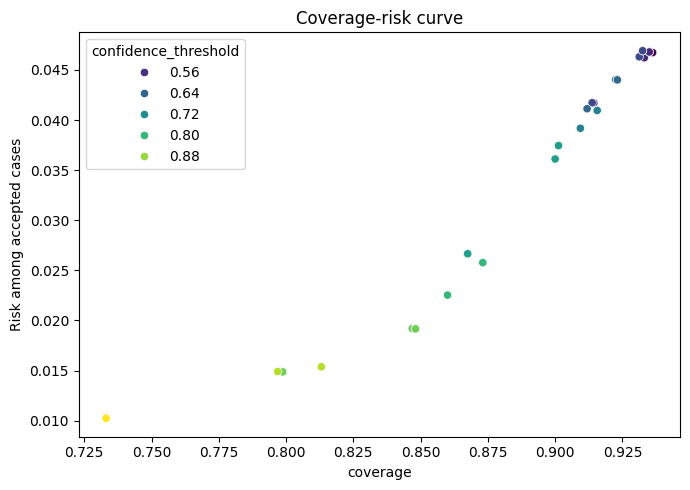

In [38]:
def selective_prediction_analysis(probabilities,labels,agreement_mask,confidence_thresholds=None,entropy_thresholds=None):
    confidence_thresholds=confidence_thresholds if confidence_thresholds is not None else np.linspace(.5,.95,10)
    entropy_thresholds=entropy_thresholds if entropy_thresholds is not None else [.25,.4,.55,.7,.85,1.]
    pred=probabilities.argmax(1); confidence=probabilities.max(1); entropy=normalized_entropy(probabilities); rows=[]
    for ct in confidence_thresholds:
        for ht in entropy_thresholds:
            accepted=agreement_mask&(confidence>=ct)&(entropy<=ht); coverage=float(accepted.mean())
            acc=float((pred[accepted]==labels[accepted]).mean()) if accepted.any() else np.nan
            rows.append({"confidence_threshold":ct,"entropy_threshold":ht,"coverage":coverage,"rejection_rate":1-coverage,
                         "selective_accuracy":acc,"accepted_error_rate":1-acc if accepted.any() else np.nan})
    return pd.DataFrame(rows)
selective_df=selective_prediction_analysis(p_ensemble,y_test,agreement)
display(selective_df.sort_values(["coverage","selective_accuracy"],ascending=[False,False]).head(12))
fig,ax=plt.subplots(figsize=(7,5)); sns.scatterplot(data=selective_df,x="coverage",y="accepted_error_rate",hue="confidence_threshold",palette="viridis",ax=ax)
ax.set(title="Coverage-risk curve",ylabel="Risk among accepted cases"); plt.tight_layout(); plt.show()
selective_df.to_csv(OUTPUT_DIRS["metrics"] / "selective_prediction_results.csv",index=False)

## 23. Experimental Reliability Score

The score combines agreement (0/1), ensemble confidence, and inverse normalized entropy. The weights are fixed descriptive choices, not learned. **This score is experimental and has not been clinically validated.**

In [39]:
reliability_score=.4*agreement.astype(float)+.3*p_ensemble.max(1)+.3*(1-h_e)
predictions_df["experimental_reliability_score"]=reliability_score
predictions_df["reliability_score_correct"]=p_ensemble.argmax(1)==y_test
print("Experimental metric; not clinical risk.")
display(predictions_df.groupby(pd.qcut(reliability_score,q=5,duplicates="drop"),observed=False)
        .agg(count=("ensemble_correct","size"),mean_score=("experimental_reliability_score","mean"),accuracy=("ensemble_correct","mean")))

Experimental metric; not clinical risk.


,count,mean_score,accuracy
"(0.103, 0.897]",320,0.650191,0.690625
"(0.897, 0.975]",320,0.945265,0.959375
"(0.975, 0.994]",320,0.987425,0.987500
"(0.994, 0.999]",320,0.997083,0.993750
"(0.999, 1.0]",320,0.999653,1.000000


## 24. Error Analysis

Inspect examples of high-confidence errors, low-confidence correct cases, high uncertainty, model disagreement, and joint errors. No cause is inferred without additional evidence.

In [40]:
predictions_df["ensemble_correct"]=p_ensemble.argmax(1)==y_test
predictions_df["resnet_correct"]=r_ok; predictions_df["vgg_correct"]=v_ok
error_groups={"high_confidence_wrong":predictions_df[~predictions_df.ensemble_correct].nlargest(3,"ensemble_confidence"),
 "low_confidence_correct":predictions_df[predictions_df.ensemble_correct].nsmallest(3,"ensemble_confidence"),
 "high_uncertainty":predictions_df.nlargest(3,"ensemble_entropy"),"disagreement":predictions_df[~predictions_df.agreement].head(3),
 "both_wrong":predictions_df[~predictions_df.resnet_correct&~predictions_df.vgg_correct].head(3)}
for group,frame in error_groups.items():
    print("\n",group,"count:",len(frame)); display(frame[["image_path","true_class","resnet_prediction","resnet_confidence","vgg_prediction","vgg_confidence",
        "ensemble_prediction","ensemble_confidence","ensemble_entropy","agreement"]])


 high_confidence_wrong count: 3


,image_path,true_class,resnet_prediction,resnet_confidence,vgg_prediction,vgg_confidence,ensemble_prediction,ensemble_confidence,ensemble_entropy,agreement
269,e:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,glioma,notumor,0.999938,notumor,0.999049,notumor,0.999493,0.003387,True
725,e:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,meningioma,notumor,0.999982,notumor,0.996836,notumor,0.998409,0.009100,True
376,e:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,glioma,notumor,0.993658,notumor,0.999538,notumor,0.996598,0.016784,True



 low_confidence_correct count: 3


,image_path,true_class,resnet_prediction,resnet_confidence,vgg_prediction,vgg_confidence,ensemble_prediction,ensemble_confidence,ensemble_entropy,agreement
277,e:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,glioma,notumor,0.465140,glioma,0.646141,glioma,0.344471,0.927278,False
550,e:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,meningioma,meningioma,0.412333,pituitary,0.469699,meningioma,0.426045,0.763688,False
454,e:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,meningioma,glioma,0.741233,meningioma,0.691511,meningioma,0.460632,0.702807,False



 high_uncertainty count: 3


,image_path,true_class,resnet_prediction,resnet_confidence,vgg_prediction,vgg_confidence,ensemble_prediction,ensemble_confidence,ensemble_entropy,agreement
129,e:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,glioma,meningioma,0.460972,notumor,0.464210,meningioma,0.324487,0.977897,False
277,e:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,glioma,notumor,0.465140,glioma,0.646141,glioma,0.344471,0.927278,False
127,e:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,glioma,meningioma,0.466768,meningioma,0.481817,meningioma,0.474292,0.909970,True



 disagreement count: 3


,image_path,true_class,resnet_prediction,resnet_confidence,vgg_prediction,vgg_confidence,ensemble_prediction,ensemble_confidence,ensemble_entropy,agreement
0,e:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,glioma,notumor,0.943400,glioma,0.957191,glioma,0.491478,0.576578,False
3,e:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,glioma,glioma,0.718602,meningioma,0.597945,glioma,0.527185,0.669357,False
18,e:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,glioma,meningioma,0.946892,notumor,0.933020,meningioma,0.500823,0.535360,False



 both_wrong count: 3


,image_path,true_class,resnet_prediction,resnet_confidence,vgg_prediction,vgg_confidence,ensemble_prediction,ensemble_confidence,ensemble_entropy,agreement
4,e:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,glioma,notumor,0.577821,notumor,0.744944,notumor,0.661382,0.586311,True
8,e:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,glioma,meningioma,0.916778,meningioma,0.873951,meningioma,0.895364,0.253201,True
11,e:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,glioma,meningioma,0.960076,meningioma,0.759703,meningioma,0.859890,0.331014,True


## 25. Statistical Comparison

McNemar's exact test compares paired correctness outcomes on the same samples. A paired bootstrap estimates the accuracy difference (ResNet50 − VGG16). Statistical significance is not practical or clinical significance.

In [41]:
both_correct=int(np.sum(r_ok&v_ok)); r_only=int(np.sum(r_ok&~v_ok)); v_only=int(np.sum(~r_ok&v_ok)); both_wrong=int(np.sum(~r_ok&~v_ok))
discordant=r_only+v_only
mcnemar_p=float(binomtest(min(r_only,v_only),n=discordant,p=.5,alternative="two-sided").pvalue) if discordant else 1.
def paired_bootstrap_accuracy_difference(a,b,n_boot=2000,seed=SEED):
    rng=np.random.default_rng(seed); diffs=np.empty(n_boot); n=len(a)
    for j in range(n_boot):
        idx=rng.integers(0,n,size=n); diffs[j]=a[idx].mean()-b[idx].mean()
    return float(a.mean()-b.mean()),tuple(np.quantile(diffs,[.025,.975]).tolist())
difference,difference_ci=paired_bootstrap_accuracy_difference(r_ok,v_ok)
statistical_results={"both_correct":both_correct,"resnet_only_correct":r_only,"vgg_only_correct":v_only,"both_wrong":both_wrong,
 "mcnemar_exact_p_value":mcnemar_p,"accuracy_difference_resnet_minus_vgg":difference,"paired_bootstrap_95ci":difference_ci}
print(json.dumps(statistical_results,indent=2)); (OUTPUT_DIRS["metrics"] / "statistical_comparison.json").write_text(json.dumps(statistical_results,indent=2))

{
  "both_correct": 1428,
  "resnet_only_correct": 51,
  "vgg_only_correct": 27,
  "both_wrong": 94,
  "mcnemar_exact_p_value": 0.008771714457060136,
  "accuracy_difference_resnet_minus_vgg": 0.014999999999999902,
  "paired_bootstrap_95ci": [
    0.004375000000000018,
    0.026249999999999996
  ]
}


299

## 26. Final Comprehensive Comparison

In [42]:
comparison_rows=[]
for name,result in [("ResNet50",resnet_eval),("VGG16",vgg_eval),("Simple Ensemble",ensemble_eval),("Adaptive/Confidence Ensemble",adaptive_eval)]:
    comparison_rows.append({"method":name,"accuracy":result["accuracy"],"macro_f1":result["macro_f1"],"weighted_f1":result["weighted_f1"],
        "roc_auc_ovr_macro":result["roc_auc_ovr_macro"],"ECE":result["ece"],"Brier":result["brier_score"],
        "average_normalized_entropy":result["mean_normalized_entropy"]})
final_comparison=pd.DataFrame(comparison_rows); display(final_comparison)
final_comparison.to_csv(OUTPUT_DIR / "final_model_comparison.csv",index=False)

,method,accuracy,macro_f1,weighted_f1,roc_auc_ovr_macro,ECE,Brier,average_normalized_entropy
0,ResNet50,0.924375,0.922594,0.922594,0.983320,0.044597,0.128593,0.074209
1,VGG16,0.909375,0.907603,0.907603,0.981862,0.026959,0.134406,0.147392
2,Simple Ensemble,0.926250,0.924659,0.924659,0.985258,0.011900,0.116040,0.131991
3,Adaptive/Confidence Ensemble,0.926250,0.924688,0.924688,0.985325,0.016457,0.116446,0.125543


## 27. Research Findings

This section generates concise statements exclusively from measured outputs.

In [43]:
best_individual=max([("ResNet50",resnet_eval["accuracy"]),("VGG16",vgg_eval["accuracy"])],key=lambda x:x[1])
best_f1=max([("ResNet50",resnet_eval["macro_f1"]),("VGG16",vgg_eval["macro_f1"])],key=lambda x:x[1])
ensemble_delta=ensemble_eval["accuracy"]-max(resnet_eval["accuracy"],vgg_eval["accuracy"])
ensemble_f1_delta=ensemble_eval["macro_f1"]-max(resnet_eval["macro_f1"],vgg_eval["macro_f1"])
ok_entropy=predictions_df.loc[predictions_df.ensemble_correct,"ensemble_entropy"].mean()
err_entropy=predictions_df.loc[~predictions_df.ensemble_correct,"ensemble_entropy"].mean()
agree_error=float((~predictions_df.loc[predictions_df.agreement,"ensemble_correct"]).mean()) if predictions_df.agreement.any() else np.nan
disagree_error=float((~predictions_df.loc[~predictions_df.agreement,"ensemble_correct"]).mean()) if (~predictions_df.agreement).any() else np.nan
pert=robustness_df[robustness_df.perturbation!="Original"].groupby("perturbation").accuracy.mean()
findings=[f"Best individual accuracy: {best_individual[0]} ({best_individual[1]:.4f}); best macro-F1: {best_f1[0]} ({best_f1[1]:.4f}).",
 f"Ensemble accuracy/macro-F1 difference from stronger individual: {ensemble_delta:+.4f}/{ensemble_f1_delta:+.4f}.",
 f"Agreement {agreement_rate:.4f}; disagreement {disagreement_rate:.4f}.",
 f"Ensemble error rate on agreeing/disagreeing cases: {agree_error:.4f}/{disagree_error:.4f}.",
 f"Mean ensemble entropy on correct/incorrect predictions: {ok_entropy:.4f}/{err_entropy:.4f}.",
 f"Test ECE ResNet/VGG/ensemble: {resnet_eval['ece']:.4f}/{vgg_eval['ece']:.4f}/{ensemble_eval['ece']:.4f}; lower ECE is better, but no validation calibration was fit." if not has_validation else f"Validation-fitted temperatures: {temperatures}.",
 f"Lowest mean robustness accuracy: {pert.idxmin()}" if len(pert) else "Robustness comparison unavailable.",
 f"Mean sampled explanation correlation/cosine: {explanation_similarity_df.heatmap_correlation.mean():.4f}/{explanation_similarity_df.cosine_similarity.mean():.4f}." if len(explanation_similarity_df) else "Explanation comparison unavailable.",
 "Explanation similarity measures consistency only; no segmentation masks available for localization metrics.",
 "Selective thresholds are exploratory, not deployment-ready."]
for text in findings: print("-",text)
(OUTPUT_DIRS["reports"] / "research_findings.txt").write_text("\n".join(findings),encoding="utf-8")

- Best individual accuracy: ResNet50 (0.9244); best macro-F1: ResNet50 (0.9226).
- Ensemble accuracy/macro-F1 difference from stronger individual: +0.0019/+0.0021.
- Agreement 0.9375; disagreement 0.0625.
- Ensemble error rate on agreeing/disagreeing cases: 0.0480/0.4600.
- Mean ensemble entropy on correct/incorrect predictions: 0.1058/0.4611.
- Test ECE ResNet/VGG/ensemble: 0.0446/0.0270/0.0119; lower ECE is better, but no validation calibration was fit.
- Lowest mean robustness accuracy: Gaussian noise
- Mean sampled explanation correlation/cosine: 0.0174/0.3317.
- Explanation similarity measures consistency only; no segmentation masks available for localization metrics.
- Selective thresholds are exploratory, not deployment-ready.


723

## 28. Research Contribution, Limitations, and Conclusion

### Contribution demonstrated

A reusable framework for dual-model comparison, probability soft-voting, disagreement, entropy, calibration diagnostics, Grad-CAM comparison, controlled perturbations, selective prediction, paired statistics, and output export.

### Limitations

Dataset size/diversity and provenance may limit generalizability; folder layout does not establish patient-level separation or exclude leakage. No validation split is available, so ensemble weights/calibration parameters/operating thresholds cannot be properly tuned. Equal voting is prespecified. No external cohort, clinical metadata, or segmentation masks are supplied; external validation is **not performed due to dataset availability**. Domain shift remains untested. Grad-CAM is coarse and not tumor localization proof. Entropy is an imperfect uncertainty proxy; models may share bias/errors. Synthetic image degradation does not represent every real scanner variation. Nothing here is clinically validated.

The conclusions apply only to these checkpoints and this test set. Future work requires patient-level splitting, a separate validation cohort, segmentation masks where appropriate, and independent external testing.

## 29. Save Results and Reproducibility

Save predictions, configuration, reports, and analysis tables beneath `outputs/` (`figures`, `metrics`, `predictions`, `explanations`, `robustness`, `reports`).

In [44]:
predictions_df.to_csv(OUTPUT_DIRS["predictions"] / "dual_model_predictions.csv",index=False)
config={"project_dir":str(PROJECT_DIR.resolve()),"dataset_dir":str(DATASET_DIR.resolve()),"train_dir":str(TRAIN_DIR.resolve()),
 "validation_dir":str(VAL_DIR.resolve()) if has_validation else None,"test_dir":str(TEST_DIR.resolve()),
 "resnet_model_path":str(RESNET_MODEL_PATH.resolve()),"vgg16_model_path":str(VGG16_MODEL_PATH.resolve()),
 "image_size":list(IMG_SIZE),"batch_size":BATCH_SIZE,"class_names":CLASS_NAMES,"seed":SEED,
 "input_preprocessing":INPUT_PREPROCESSING,"validation_available":bool(has_validation),"ensemble_alpha_resnet":float(best_alpha),
 "robustness_sample_count":int(len(robust_idx)),"test_sample_count":int(len(y_test)),"python_version":platform.python_version(),
 "tensorflow_version":tf.__version__,"numpy_version":np.__version__,"pandas_version":pd.__version__,
 "sklearn_version":__import__("sklearn").__version__,"gpu_devices":[d.name for d in tf.config.list_physical_devices("GPU")]}
(OUTPUT_DIRS["reports"] / "experiment_configuration.json").write_text(json.dumps(config,indent=2),encoding="utf-8")
final_comparison.to_csv(OUTPUT_DIR / "final_model_comparison.csv",index=False)
for name,path in OUTPUT_DIRS.items(): print(name,path.resolve())
display(final_comparison)

figures E:\SEM5\ERA\ERA_Project\Brain_Tumor\outputs\figures
metrics E:\SEM5\ERA\ERA_Project\Brain_Tumor\outputs\metrics
predictions E:\SEM5\ERA\ERA_Project\Brain_Tumor\outputs\predictions
explanations E:\SEM5\ERA\ERA_Project\Brain_Tumor\outputs\explanations
robustness E:\SEM5\ERA\ERA_Project\Brain_Tumor\outputs\robustness
reports E:\SEM5\ERA\ERA_Project\Brain_Tumor\outputs\reports


,method,accuracy,macro_f1,weighted_f1,roc_auc_ovr_macro,ECE,Brier,average_normalized_entropy
0,ResNet50,0.924375,0.922594,0.922594,0.983320,0.044597,0.128593,0.074209
1,VGG16,0.909375,0.907603,0.907603,0.981862,0.026959,0.134406,0.147392
2,Simple Ensemble,0.926250,0.924659,0.924659,0.985258,0.011900,0.116040,0.131991
3,Adaptive/Confidence Ensemble,0.926250,0.924688,0.924688,0.985325,0.016457,0.116446,0.125543
